# 04 — Testing: clean and degraded images, and the 8-bit low-resource model

**What this notebook does.** It takes the models trained and locked in notebook 03 and
tests them, once, on the 378 test patches that no earlier step has used. It answers three questions:

1. **How well does the model work on clean test images?** Fine-tuned model compared with the baseline.
2. **How well does it hold up when the images are worse?** The same test patches are degraded in
   15 ways that mimic low-resource conditions (JPEG compression, low resolution, noise, contrast and
   brightness shifts, and a phone photograph of printed film), and every model is re-scored.
3. **What does the low-resource version cost?** The fine-tuned model is converted to an 8-bit
   TensorFlow Lite model, which is about four times smaller and runs on a CPU. We measure how much
   accuracy that loses, whether its probabilities stay calibrated, and how long it takes per image.

**Rule.** Nothing is tuned here. The temperature and threshold come from `locked.json` (notebook 03).
The one value fitted in this notebook, the 8-bit model's temperature, is fitted on the
**validation** set, never on the test set.

**Inputs** (Kaggle: *Add Input*)

| Input | What it provides |
|---|---|
| Notebook 02 output | `patches/` (the 1,696 patch images and outlines) and `patch_index.csv` |
| Notebook 03 output | `model/model.keras`, `model/baseline_logreg.joblib`, `model/locked.json` |

**Settings.** Accelerator: GPU. Internet: On (the baseline needs the ImageNet weights).
Run with *Save Version → Save & Run All* so the outputs are kept.

**Outputs** (in `/kaggle/working/test_results`): result tables with 95% confidence intervals,
figures, the two TensorFlow Lite models, and a script to time the 8-bit model on a laptop.

## 0. Setup
Imports, settings, and locating the two inputs. `n_boot` is the number of bootstrap resamples
used for confidence intervals.

In [1]:
import os, json, time, random, warnings, platform
from pathlib import Path
import numpy as np, pandas as pd, cv2, joblib
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score, average_precision_score
import tensorflow as tf, keras

warnings.filterwarnings("ignore")
try: display
except NameError: display = print          # outside a notebook
SMOKE = os.environ.get("SMOKE") == "1"            # tiny test run only; ignore on Kaggle
CFG = dict(seed=42, img=224, n_boot=100 if SMOKE else 1000)

def find(name):
    root = os.environ.get("INPUT_DIR", "/kaggle/input")
    hits = sorted(os.path.join(d, name) for d, _, files in os.walk(root, followlinks=True) if name in files)
    assert hits, f"{name} not found. Use 'Add Input' to attach the notebook that produced it."
    return str(hits[0])

INDEX = find("patch_index.csv"); PATCHES = os.path.dirname(INDEX)
LOCKED = find("locked.json"); MODEL_DIR = os.path.dirname(LOCKED)
OUT = os.environ.get("OUT_DIR", "/kaggle/working/test_results"); os.makedirs(OUT, exist_ok=True)

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); tf.random.set_seed(CFG["seed"])
print("Patches from:", PATCHES); print("Models from: ", MODEL_DIR)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Patches from: /kaggle/input/notebooks/abdussalamhameedat/02-patch-notebook/patches
Models from:  /kaggle/input/notebooks/abdussalamhameedat/03-training-and-calibration/model
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load the locked models and settings
- **Fine-tuned model**: MobileNetV2 trained in notebook 03.
- **Baseline**: the logistic regression from notebook 03. It needs the *untrained* MobileNetV2
  to turn each patch into 1,280 numbers, so that network is rebuilt here exactly as before.
- **Locked settings**: the temperature (calibration) and threshold (decision cut-off).

In [2]:
lock = json.load(open(LOCKED))
T, THR = lock["temperature"], lock["threshold"]
model = keras.models.load_model(os.path.join(MODEL_DIR, "model.keras"))
baseline = joblib.load(os.path.join(MODEL_DIR, "baseline_logreg.joblib"))
S = lock["config"]["img"]

frozen = keras.applications.MobileNetV2(input_shape=(S, S, 3), include_top=False, weights="imagenet", pooling="avg")
def base_features(X):                         # same steps as notebook 03: 0..255 -> -1..1 -> frozen network
    return frozen.predict(rgb(X) / 127.5 - 1.0, batch_size=64, verbose=0)

print(f"Locked temperature {T:.3f} | threshold {THR:.3f} | target sensitivity {lock['target_sensitivity']}")
print(f"Validation AUROC from notebook 03: fine-tuned {lock['val_auroc_finetuned']:.3f}, baseline {lock['val_auroc_baseline']:.3f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Locked temperature 1.208 | threshold 0.279 | target sensitivity 0.9
Validation AUROC from notebook 03: fine-tuned 0.767, baseline 0.733


## 2. Load the validation and test patches
Each 16-bit patch is converted to 8-bit with the same rule as notebook 03 (divide by 257) and kept
**at its original size**. Degradations are applied at this size and the image is resized to
224×224 afterwards, which is what would happen to a real degraded image fed to the model.

In [3]:
idx = pd.read_csv(INDEX)
def native(rel):
    im = cv2.imread(os.path.join(PATCHES, rel), cv2.IMREAD_UNCHANGED)
    return np.round(im / 257.0).astype(np.uint8) if im.dtype == np.uint16 else im
def to_input(im):
    return cv2.resize(im, (S, S), interpolation=cv2.INTER_AREA)
rgb = lambda X: np.repeat(X[..., None], 3, axis=-1).astype("float32")

d_va = idx[idx.split == "val"].reset_index(drop=True); d_te = idx[idx.split == "test"].reset_index(drop=True)
N_va = [native(p) for p in d_va.img_path]; N_te = [native(p) for p in d_te.img_path]
X_va = np.stack([to_input(im) for im in N_va]); X_te = np.stack([to_input(im) for im in N_te])
y_va = d_va.label.values.astype(int); y_te = d_te.label.values.astype(int); g_te = d_te.patient_id.values
print(f"Validation: {len(y_va)} patches ({y_va.sum()} malignant) | "
      f"Test: {len(y_te)} patches from {len(set(g_te))} patients ({y_te.sum()} malignant)")
assert not set(d_te.patient_id) & set(idx[idx.split != "test"].patient_id), "A test patient also appears in training or validation"

Validation: 197 patches (105 malignant) | Test: 378 patches from 201 patients (147 malignant)


## 3. The degradations
Each one imitates something that happens to images in a low-resource setting. Severity rises
within each family. Every degradation uses a fixed random seed per image, so reruns give the
same degraded images.

| Family | Levels | Imitates |
|---|---|---|
| JPEG compression | quality 90, 50, 20, 10 | Images saved or sent compressed (e.g. over messaging apps) |
| Lower resolution | half, quarter | Low-resolution scanning or screenshots |
| Noise | SD 5, 15, 25 (of 255) | Poor sensors or scanners |
| Contrast | ×0.7, ×0.5 | Under-exposed or faded film |
| Brightness | +30, −30 | Over- or under-exposed images |
| Phone photo of film | mild, strong | Photographing a film on a light box: blur, slight tilt, uneven lighting, then JPEG |

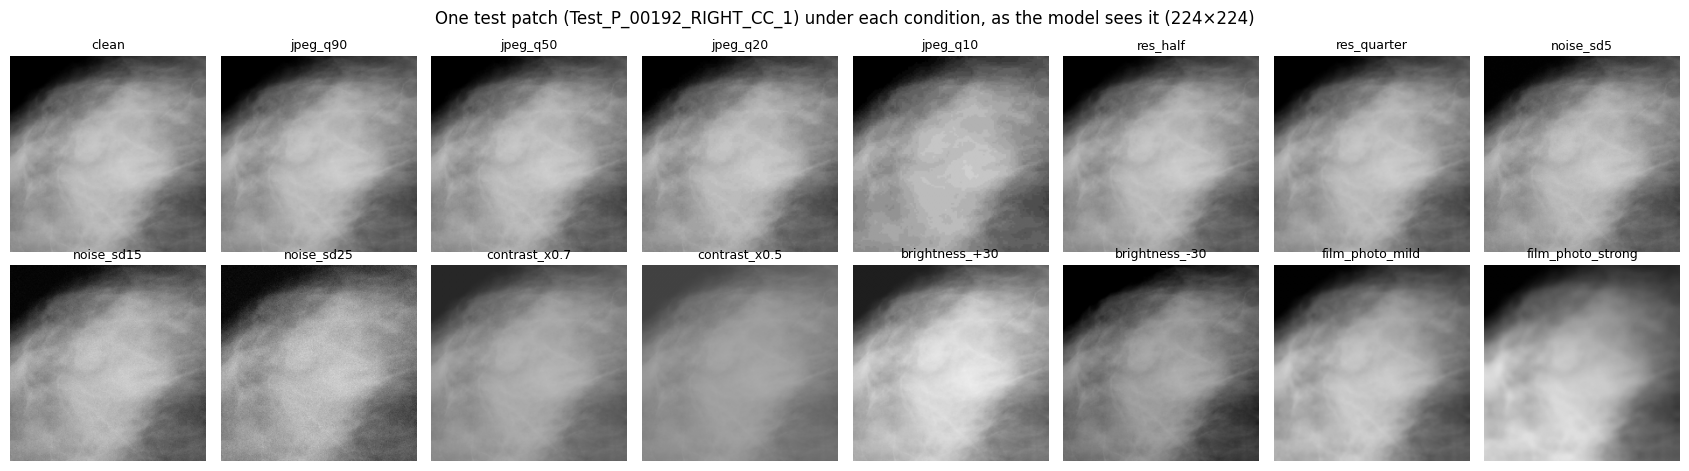

In [4]:
def jpeg(q):
    return lambda im, r: cv2.imdecode(cv2.imencode(".jpg", im, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_GRAYSCALE)
def lowres(f):
    def fn(im, r):
        h, w = im.shape; s = cv2.resize(im, (max(8, int(w * f)), max(8, int(h * f))), interpolation=cv2.INTER_AREA)
        return cv2.resize(s, (w, h), interpolation=cv2.INTER_LINEAR)
    return fn
def noise(sd):    return lambda im, r: np.clip(im + r.normal(0, sd, im.shape), 0, 255).astype(np.uint8)
def contrast(c):  return lambda im, r: np.clip((im.astype(np.float32) - im.mean()) * c + im.mean(), 0, 255).astype(np.uint8)
def bright(b):    return lambda im, r: np.clip(im.astype(np.float32) + b, 0, 255).astype(np.uint8)
def film_photo(k):
    def fn(im, r):
        h, w = im.shape
        out = cv2.GaussianBlur(im, (0, 0), 0.004 * k * max(h, w) + 0.5)                       # focus blur
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        dst = (src + r.uniform(-1, 1, (4, 2)) * 0.03 * k * np.array([w, h])).astype(np.float32)  # camera tilt
        out = cv2.warpPerspective(out, cv2.getPerspectiveTransform(src, dst), (w, h), borderMode=cv2.BORDER_REFLECT)
        a = r.uniform(0, 2 * np.pi); yy, xx = np.mgrid[0:h, 0:w]
        grad = (np.cos(a) * (xx / w - .5) + np.sin(a) * (yy / h - .5)) * 0.35 * k                # uneven lighting
        out = np.clip(out.astype(np.float32) * (1 + grad), 0, 255).astype(np.uint8)
        return jpeg(70)(out, r)                                                                   # phone saves as JPEG
    return fn

CONDITIONS = {"clean": None,
    "jpeg_q90": jpeg(90), "jpeg_q50": jpeg(50), "jpeg_q20": jpeg(20), "jpeg_q10": jpeg(10),
    "res_half": lowres(0.5), "res_quarter": lowres(0.25),
    "noise_sd5": noise(5), "noise_sd15": noise(15), "noise_sd25": noise(25),
    "contrast_x0.7": contrast(0.7), "contrast_x0.5": contrast(0.5),
    "brightness_+30": bright(30), "brightness_-30": bright(-30),
    "film_photo_mild": film_photo(1), "film_photo_strong": film_photo(2)}

def test_images(cond):
    if CONDITIONS[cond] is None: return X_te
    return np.stack([to_input(CONDITIONS[cond](im, np.random.default_rng(CFG["seed"] + i))) for i, im in enumerate(N_te)])

# Show one test patch under every condition, so readers can see what each level looks like
k = int(np.argmax([im.size for im in N_te[:50]]))
fig, ax = plt.subplots(2, 8, figsize=(17, 4.8))
for a, cond in zip(ax.ravel(), CONDITIONS):
    im = N_te[k] if CONDITIONS[cond] is None else CONDITIONS[cond](N_te[k], np.random.default_rng(CFG["seed"] + k))
    a.imshow(to_input(im), cmap="gray", vmin=0, vmax=255); a.set_title(cond, fontsize=9); a.axis("off")
plt.suptitle(f"One test patch ({d_te.roi_id[k]}) under each condition, as the model sees it (224×224)")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_degradation_examples.png"), dpi=130); plt.show()

## 4. Build the 8-bit low-resource model
The fine-tuned model is converted to TensorFlow Lite twice: once keeping 32-bit numbers (to check
the conversion itself changes nothing), and once with weights and activations stored as 8-bit
integers. The 8-bit conversion needs ~200 example images to set its number ranges; these come
from the **training** set.

Quantising can shift the model's probabilities, so the 8-bit model gets its **own temperature,
refitted on the validation set**. It is reported both ways: with notebook 03's temperature and
with its own.

In [5]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
def nll(z, y, t):
    p = np.clip(sigmoid(z / t), 1e-7, 1 - 1e-7); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

sm = os.path.join(OUT, "saved_model")
if not os.path.exists(sm): model.export(sm, verbose=0)
d_tr = idx[idx.split == "train"].sample(min(200, int((idx.split == "train").sum())), random_state=CFG["seed"])
rep = rgb(np.stack([to_input(native(p)) for p in d_tr.img_path]))

def convert(quantise):
    conv = tf.lite.TFLiteConverter.from_saved_model(sm)
    if quantise:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = lambda: ([x[None]] for x in rep)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    return conv.convert()
TFL = {}
for name, q in (("float32", False), ("int8", True)):
    TFL[name] = os.path.join(OUT, f"model_{name}.tflite"); open(TFL[name], "wb").write(convert(q))
    print(f"{name}: {os.path.getsize(TFL[name]) / 1e6:.2f} MB")

def interpreter(path, threads):
    try: I = tf.lite.Interpreter(model_path=path, num_threads=threads)
    except Exception:
        from ai_edge_litert.interpreter import Interpreter; I = Interpreter(model_path=path, num_threads=threads)
    I.allocate_tensors(); return I
def tfl_scores(path, X):
    I = interpreter(path, os.cpu_count()); i, o = I.get_input_details()[0]["index"], I.get_output_details()[0]["index"]
    out = []
    for x in rgb(X):
        I.set_tensor(i, x[None]); I.invoke(); out.append(float(I.get_tensor(o).ravel()[0]))
    return np.array(out)
def keras_scores(X): return model.predict(rgb(X), batch_size=64, verbose=0).ravel()

zq_va = tfl_scores(TFL["int8"], X_va)
T_Q = float(minimize_scalar(lambda t: nll(zq_va, y_va, t), bounds=(0.05, 20), method="bounded").x)
print(f"Temperature: fine-tuned (locked) {T:.3f} | 8-bit model, refitted on validation {T_Q:.3f}")

# The baseline needs its own threshold for sensitivity/specificity: same rule, fitted on validation
pb_va = baseline.predict_proba(base_features(X_va))[:, 1]
okb = [t for t in np.unique(pb_va) if (pb_va[y_va == 1] >= t).mean() >= lock["target_sensitivity"]]
THR_B = float(max(okb)) if okb else 0.5
print(f"Baseline threshold (validation, same 90% sensitivity rule): {THR_B:.3f}")

INFO:tensorflow:Assets written to: /kaggle/working/test_results/saved_model/assets


INFO:tensorflow:Assets written to: /kaggle/working/test_results/saved_model/assets


float32: 8.88 MB


fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


int8: 2.72 MB
Temperature: fine-tuned (locked) 1.208 | 8-bit model, refitted on validation 1.326
Baseline threshold (validation, same 90% sensitivity rule): 0.056


## 5. Score every model on every test condition

**Models compared**

| Name | What it is |
|---|---|
| `fine_tuned` | The main model, locked temperature and threshold |
| `int8` | The 8-bit TensorFlow Lite model, its own temperature (fitted on validation), locked threshold |
| `baseline` | Frozen MobileNetV2 features + logistic regression, its own validation threshold |
| `int8_lockedT` | The 8-bit model with the fine-tuned model's temperature (clean only) |
| `float_tflite` | The 32-bit TensorFlow Lite copy (clean only; should match `fine_tuned`) |

**Measures**

| Measure | Meaning |
|---|---|
| AUROC | Chance a random malignant patch is scored above a random benign one (0.5 = guessing) |
| AUPRC | Average precision; the same idea, focused on the malignant class |
| Sensitivity | Share of malignant masses flagged, at the threshold |
| Specificity | Share of benign masses correctly cleared, at the threshold |
| ECE | Calibration error: the average gap between the probability shown and how often it is right (0 = perfect) |
| Brier | Mean squared error of the probabilities (lower is better) |

**Confidence intervals.** 95% intervals from bootstrapping **by patient**: patients (not single
images) are resampled 1,000 times, because one patient's two views are not independent.

In [6]:
def ece(y, p, bins=10):
    e = 0.0
    for b in range(bins):
        lo, hi = b / bins, (b + 1) / bins
        m = (p >= lo) & ((p < hi) if b < bins - 1 else (p <= hi))
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e
def metrics(y, p, thr):
    pred = p >= thr
    return dict(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p),
                sensitivity=pred[y == 1].mean(), specificity=(~pred[y == 0]).mean(),
                ece=ece(y, p), brier=np.mean((p - y) ** 2))

rng = np.random.default_rng(CFG["seed"]); pids = np.unique(g_te); rows_of = {p: np.where(g_te == p)[0] for p in pids}
BOOT = []                                     # the same resamples for every model and condition, so they are comparable
while len(BOOT) < CFG["n_boot"]:
    s = np.concatenate([rows_of[p] for p in rng.choice(pids, len(pids))])
    if 0 < y_te[s].sum() < len(s): BOOT.append(s)

def with_ci(p, thr):
    est = metrics(y_te, p, thr); b = pd.DataFrame([metrics(y_te[s], p[s], thr) for s in BOOT])
    return {**{k: float(v) for k, v in est.items()},
            **{k + "_lo": float(b[k].quantile(.025)) for k in est}, **{k + "_hi": float(b[k].quantile(.975)) for k in est}}

PROBS, rows = {}, []
t0 = time.time()
for cond in CONDITIONS:
    Xc = test_images(cond); zq = tfl_scores(TFL["int8"], Xc)
    preds = {"fine_tuned": (sigmoid(keras_scores(Xc) / T), THR),
             "int8": (sigmoid(zq / T_Q), THR),
             "baseline": (baseline.predict_proba(base_features(Xc))[:, 1], THR_B)}
    if cond == "clean":
        preds["int8_lockedT"] = (sigmoid(zq / T), THR)
        preds["float_tflite"] = (sigmoid(tfl_scores(TFL["float32"], Xc) / T), THR)
    for m, (p, thr) in preds.items():
        PROBS[(m, cond)] = p; rows.append(dict(model=m, condition=cond, **with_ci(p, thr)))
    print(f"{cond:18s}", "  ".join(f"{m} {roc_auc_score(y_te, p):.3f}" for m, (p, _) in preds.items()), flush=True)
RES = pd.DataFrame(rows); RES.to_csv(os.path.join(OUT, "results_test.csv"), index=False)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min. Full table: results_test.csv")

clean              fine_tuned 0.778  int8 0.775  baseline 0.719  int8_lockedT 0.775  float_tflite 0.778
jpeg_q90           fine_tuned 0.782  int8 0.780  baseline 0.726
jpeg_q50           fine_tuned 0.772  int8 0.755  baseline 0.694
jpeg_q20           fine_tuned 0.694  int8 0.653  baseline 0.596
jpeg_q10           fine_tuned 0.549  int8 0.580  baseline 0.466
res_half           fine_tuned 0.789  int8 0.774  baseline 0.710
res_quarter        fine_tuned 0.769  int8 0.768  baseline 0.683
noise_sd5          fine_tuned 0.759  int8 0.757  baseline 0.692
noise_sd15         fine_tuned 0.702  int8 0.713  baseline 0.624
noise_sd25         fine_tuned 0.639  int8 0.628  baseline 0.538
contrast_x0.7      fine_tuned 0.762  int8 0.779  baseline 0.688
contrast_x0.5      fine_tuned 0.738  int8 0.753  baseline 0.640
brightness_+30     fine_tuned 0.778  int8 0.772  baseline 0.707
brightness_-30     fine_tuned 0.774  int8 0.779  baseline 0.717
film_photo_mild    fine_tuned 0.742  int8 0.763  baseline 0.650


## 6. Results on clean test images
The headline table. Each cell is the estimate with its 95% confidence interval.

In [7]:
fmt = lambda r, k: f"{r[k]:.3f} ({r[k + '_lo']:.3f}–{r[k + '_hi']:.3f})"
def table(models, conds, keys=("auroc", "sensitivity", "specificity", "ece")):
    t = RES[RES.model.isin(models) & RES.condition.isin(conds)].copy()
    t["order"] = t.model.map({m: i for i, m in enumerate(models)}) * 100 + t.condition.map({c: i for i, c in enumerate(CONDITIONS)})
    t = t.sort_values("order")
    return pd.DataFrame({"model": t.model, "condition": t.condition,
                         **{k: [fmt(r, k) for _, r in t.iterrows()] for k in keys}}).reset_index(drop=True)

clean = table(["fine_tuned", "baseline", "int8", "int8_lockedT", "float_tflite"], ["clean"],
              ("auroc", "auprc", "sensitivity", "specificity", "ece", "brier"))
clean.to_csv(os.path.join(OUT, "table_clean.csv"), index=False); display(clean)

,model,condition,auroc,auprc,sensitivity,specificity,ece,brier
0,fine_tuned,clean,0.778 (0.721–0.835),0.697 (0.602–0.783),0.918 (0.870–0.960),0.312 (0.250–0.373),0.074 (0.054–0.131),0.188 (0.169–0.208)
1,baseline,clean,0.719 (0.663–0.774),0.619 (0.509–0.717),0.905 (0.857–0.947),0.312 (0.249–0.370),0.195 (0.159–0.247),0.252 (0.214–0.288)
2,int8,clean,0.775 (0.717–0.832),0.663 (0.564–0.759),0.959 (0.916–0.993),0.242 (0.181–0.305),0.095 (0.059–0.144),0.195 (0.176–0.214)
3,int8_lockedT,clean,0.775 (0.717–0.832),0.663 (0.564–0.759),0.932 (0.882–0.973),0.286 (0.218–0.347),0.080 (0.054–0.133),0.193 (0.173–0.214)
4,float_tflite,clean,0.778 (0.721–0.835),0.697 (0.602–0.783),0.918 (0.870–0.960),0.312 (0.250–0.373),0.074 (0.054–0.131),0.188 (0.169–0.208)


### Paired comparisons on clean test images
Differences in AUROC, computed on the same bootstrap resamples so the interval reflects the
difference itself. An interval that includes 0 means the difference could be chance.
- **Fine-tuned − baseline**: what fine-tuning added.
- **8-bit − fine-tuned**: what quantisation cost.

In [8]:
def paired(a, b):
    pa, pb = PROBS[(a, "clean")], PROBS[(b, "clean")]
    d = np.array([roc_auc_score(y_te[s], pa[s]) - roc_auc_score(y_te[s], pb[s]) for s in BOOT])
    return dict(comparison=f"{a} − {b}", auroc_difference=round(roc_auc_score(y_te, pa) - roc_auc_score(y_te, pb), 3),
                ci_low=round(float(np.quantile(d, .025)), 3), ci_high=round(float(np.quantile(d, .975)), 3))
PAIRED = pd.DataFrame([paired("fine_tuned", "baseline"), paired("int8", "fine_tuned")])
PAIRED.to_csv(os.path.join(OUT, "table_paired.csv"), index=False); display(PAIRED)

,comparison,auroc_difference,ci_low,ci_high
0,fine_tuned − baseline,0.059,0.009,0.111
1,int8 − fine_tuned,-0.003,-0.029,0.022


## 7. Results under degradation
AUROC shows whether the model can still *rank* malignant above benign. Sensitivity and
specificity show what happens to *decisions* at the locked threshold: a degradation can leave
AUROC almost unchanged yet shift every probability up or down, so the model suddenly misses
cancers or flags everything. ECE shows whether the probabilities stay honest.

In [9]:
deg = table(["fine_tuned", "int8", "baseline"], list(CONDITIONS))
deg.to_csv(os.path.join(OUT, "table_degraded.csv"), index=False)
pd.set_option("display.max_rows", 100); display(deg)

,model,condition,auroc,sensitivity,specificity,ece
0,fine_tuned,clean,0.778 (0.721–0.835),0.918 (0.870–0.960),0.312 (0.250–0.373),0.074 (0.054–0.131)
1,fine_tuned,jpeg_q90,0.782 (0.724–0.838),0.939 (0.897–0.974),0.316 (0.250–0.379),0.086 (0.051–0.139)
2,fine_tuned,jpeg_q50,0.772 (0.717–0.826),0.973 (0.944–0.994),0.143 (0.093–0.193),0.118 (0.076–0.176)
3,fine_tuned,jpeg_q20,0.694 (0.630–0.755),0.986 (0.966–1.000),0.082 (0.039–0.124),0.148 (0.096–0.206)
4,fine_tuned,jpeg_q10,0.549 (0.483–0.623),0.993 (0.976–1.000),0.026 (0.005–0.051),0.216 (0.152–0.288)
5,fine_tuned,res_half,0.789 (0.732–0.844),0.946 (0.908–0.979),0.303 (0.233–0.365),0.097 (0.063–0.147)
6,fine_tuned,res_quarter,0.769 (0.709–0.829),0.925 (0.872–0.971),0.273 (0.210–0.335),0.085 (0.056–0.139)
7,fine_tuned,noise_sd5,0.759 (0.698–0.817),0.925 (0.878–0.968),0.199 (0.138–0.257),0.092 (0.065–0.149)
8,fine_tuned,noise_sd15,0.702 (0.634–0.768),0.837 (0.760–0.902),0.381 (0.297–0.459),0.042 (0.033–0.106)
9,fine_tuned,noise_sd25,0.639 (0.565–0.709),0.769 (0.679–0.846),0.416 (0.335–0.496),0.053 (0.036–0.121)


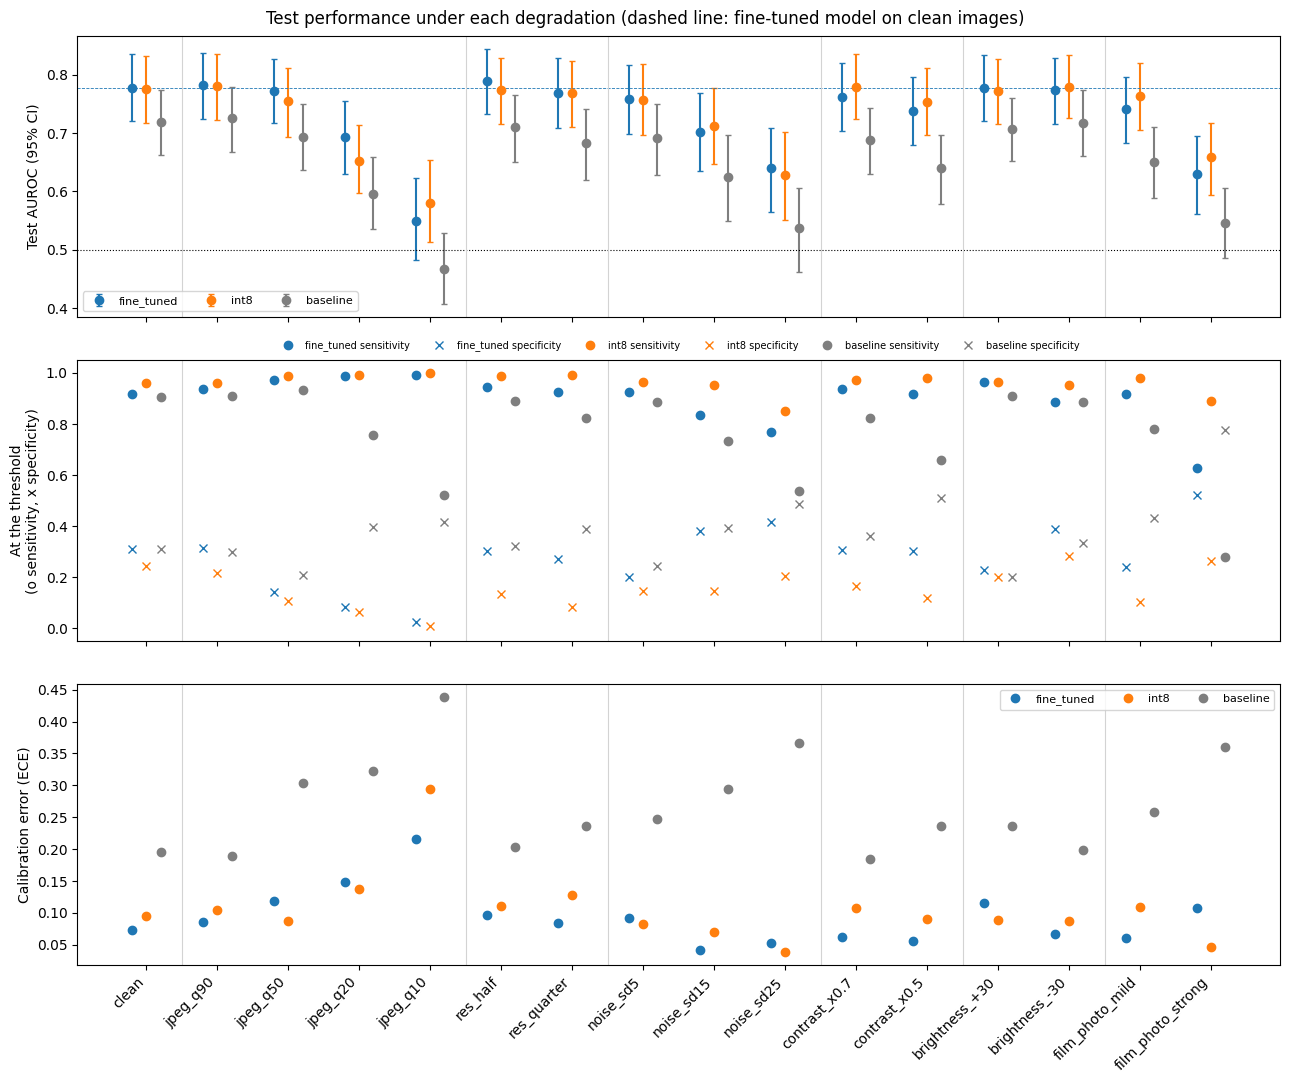

In [10]:
cond_names = list(CONDITIONS); xs = np.arange(len(cond_names))
fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
style = {"fine_tuned": ("tab:blue", -0.2), "int8": ("tab:orange", 0.0), "baseline": ("tab:grey", 0.2)}
for m, (c, dx) in style.items():
    d = RES[RES.model == m].set_index("condition").loc[cond_names]
    ax[0].errorbar(xs + dx, d.auroc, yerr=[d.auroc - d.auroc_lo, d.auroc_hi - d.auroc], fmt="o", c=c, capsize=2, label=m)
    ax[1].plot(xs + dx, d.sensitivity, "o", c=c, label=f"{m} sensitivity"); ax[1].plot(xs + dx, d.specificity, "x", c=c, label=f"{m} specificity")
    ax[2].plot(xs + dx, d.ece, "o", c=c, label=m)
ax[0].axhline(0.5, ls=":", c="k", lw=0.8); ax[0].set_ylabel("Test AUROC (95% CI)"); ax[0].legend(ncol=3, fontsize=8, loc="lower left")
ax[0].axhline(RES[(RES.model == "fine_tuned") & (RES.condition == "clean")].auroc.iloc[0], ls="--", c="tab:blue", lw=0.6)
ax[1].set_ylabel("At the threshold\n(o sensitivity, x specificity)"); ax[1].set_ylim(-0.05, 1.05)
ax[1].legend(ncol=6, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax[2].set_ylabel("Calibration error (ECE)"); ax[2].legend(ncol=3, fontsize=8)
ax[2].set_xticks(xs); ax[2].set_xticklabels(cond_names, rotation=45, ha="right")
for a in ax:
    for b in (0.5, 4.5, 6.5, 9.5, 11.5, 13.5): a.axvline(b, c="lightgrey", lw=0.8)
plt.suptitle("Test performance under each degradation (dashed line: fine-tuned model on clean images)")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_robustness.png"), dpi=140); plt.show()

## 8. Calibration on clean test images
A reliability diagram: patches are grouped by the probability shown, and each point compares that
probability (x) with the share that were actually malignant (y). Points on the dotted diagonal
mean the probabilities can be taken at face value. Groups with fewer than 10 patches are not drawn.

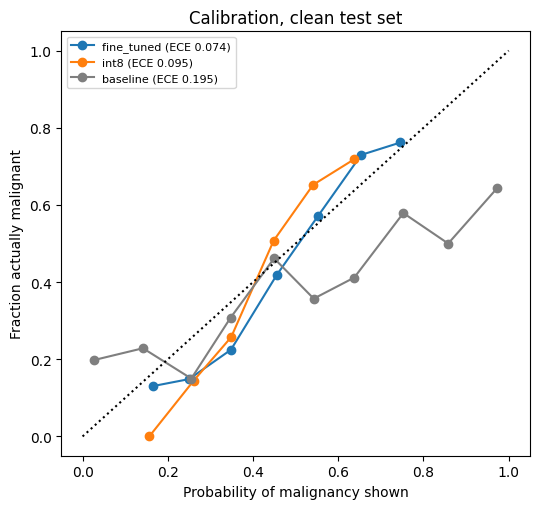

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5.2))
for m, c in (("fine_tuned", "tab:blue"), ("int8", "tab:orange"), ("baseline", "tab:grey")):
    p = PROBS[(m, "clean")]; xs_, ys_ = [], []
    for b in range(10):
        msk = (p >= b / 10) & ((p < (b + 1) / 10) if b < 9 else (p <= 1))
        if msk.sum() >= 10: xs_.append(p[msk].mean()); ys_.append(y_te[msk].mean())
    ax.plot(xs_, ys_, "o-", c=c, label=f"{m} (ECE {ece(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], ":", c="k"); ax.set_xlabel("Probability of malignancy shown"); ax.set_ylabel("Fraction actually malignant")
ax.set_title("Calibration, clean test set"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_calibration.png"), dpi=140); plt.show()

## 9. Size and speed
Time per image for one image at a time on **one CPU thread**, the slowest realistic setting.
This runs on Kaggle's CPU. For the report, run `time_on_laptop.py` (saved in the outputs) on the
actual low-resource laptop and record that machine's processor and memory alongside the result:

```
pip install ai-edge-litert numpy
python time_on_laptop.py model_int8.tflite
python time_on_laptop.py model_float32.tflite
```

In [12]:
def time_model(path, n=20 if SMOKE else 300):
    I = interpreter(path, 1); i = I.get_input_details()[0]["index"]; x = rgb(X_te[:1])
    for _ in range(20): I.set_tensor(i, x); I.invoke()
    t = []
    for _ in range(n):
        a = time.perf_counter(); I.set_tensor(i, x); I.invoke(); t.append((time.perf_counter() - a) * 1000)
    return dict(size_mb=round(os.path.getsize(path) / 1e6, 2), median_ms=round(float(np.median(t)), 1), p95_ms=round(float(np.percentile(t, 95)), 1))
SPEED = pd.DataFrame({k: time_model(v) for k, v in TFL.items()}).T
SPEED["machine"] = f"Kaggle CPU ({platform.processor() or platform.machine()}), 1 thread"
SPEED.to_csv(os.path.join(OUT, "table_speed.csv")); display(SPEED)

open(os.path.join(OUT, "time_on_laptop.py"), "w").write('''"""Time a TensorFlow Lite model on this computer, one image at a time, one CPU thread.
Usage:  pip install ai-edge-litert numpy
        python time_on_laptop.py model_int8.tflite
"""
import sys, time, platform, os, numpy as np
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    from tensorflow.lite import Interpreter
I = Interpreter(model_path=sys.argv[1], num_threads=1); I.allocate_tensors()
i = I.get_input_details()[0]["index"]; x = (np.random.rand(1, 224, 224, 3) * 255).astype("float32")
for _ in range(20): I.set_tensor(i, x); I.invoke()
t = []
for _ in range(300):
    a = time.perf_counter(); I.set_tensor(i, x); I.invoke(); t.append((time.perf_counter() - a) * 1000)
print("Machine:", platform.platform(), "|", platform.processor() or platform.machine(), "| CPU cores:", os.cpu_count())
print(f"{sys.argv[1]}: median {np.median(t):.1f} ms per image, 95th percentile {np.percentile(t, 95):.1f} ms")
''')

,size_mb,median_ms,p95_ms,machine
float32,8.88,8.0,8.9,"Kaggle CPU (x86_64), 1 thread"
int8,2.72,11.8,12.8,"Kaggle CPU (x86_64), 1 thread"


942

## 10. Save a summary
`summary.json` gathers the key numbers for the model card. All tables and figures are in the
output folder.

In [13]:
get = lambda m, c, k: float(RES[(RES.model == m) & (RES.condition == c)][k].iloc[0])
summary = dict(
    test_patches=int(len(y_te)), test_patients=int(len(pids)), test_malignant=int(y_te.sum()),
    locked_temperature=T, locked_threshold=THR, int8_temperature_refit_on_validation=T_Q, baseline_threshold=THR_B,
    clean={m: {k: get(m, "clean", k) for k in ("auroc", "auroc_lo", "auroc_hi", "sensitivity", "specificity", "ece")}
           for m in ("fine_tuned", "baseline", "int8")},
    worst_condition_fine_tuned=RES[RES.model == "fine_tuned"].sort_values("auroc").iloc[0][["condition", "auroc"]].to_dict(),
    paired=PAIRED.to_dict("records"), speed=SPEED.to_dict("index"), n_boot=CFG["n_boot"], tensorflow=tf.__version__)
json.dump(summary, open(os.path.join(OUT, "summary.json"), "w"), indent=2, default=str)
print(json.dumps(summary["clean"], indent=2)); print("\nFiles:", sorted(os.listdir(OUT)))

{
  "fine_tuned": {
    "auroc": 0.7777483287687368,
    "auroc_lo": 0.7210793616226979,
    "auroc_hi": 0.8346285825594975,
    "sensitivity": 0.9183673469387755,
    "specificity": 0.3116883116883117,
    "ece": 0.07397748451068918
  },
  "baseline": {
    "auroc": 0.7192036987955355,
    "auroc_lo": 0.6629058604876761,
    "auroc_hi": 0.7739829365312136,
    "sensitivity": 0.9047619047619048,
    "specificity": 0.3116883116883117,
    "ece": 0.19538846834902437
  },
  "int8": {
    "auroc": 0.7747150808375297,
    "auroc_lo": 0.7167126224302629,
    "auroc_hi": 0.8317410998047249,
    "sensitivity": 0.9591836734693877,
    "specificity": 0.24242424242424243,
    "ece": 0.09493931665054336
  }
}

Files: ['fig_calibration.png', 'fig_degradation_examples.png', 'fig_robustness.png', 'model_float32.tflite', 'model_int8.tflite', 'results_test.csv', 'saved_model', 'summary.json', 'table_clean.csv', 'table_degraded.csv', 'table_paired.csv', 'table_speed.csv', 'time_on_laptop.py']


## What to record from this notebook
- **Clean test results** (section 6): AUROC, sensitivity, specificity and ECE with confidence intervals for the fine-tuned model, baseline and 8-bit model.
- **Paired differences** (section 6): what fine-tuning added, and what quantisation cost.
- **Robustness** (section 7): which degradations hurt most, and whether the damage is to ranking (AUROC), decisions (sensitivity/specificity) or calibration (ECE).
- **Size and speed** (section 9), plus the laptop timing from `time_on_laptop.py`.

**Next:** notebook 05, heatmaps (Grad-CAM, Grad-CAM++, occlusion) compared with the outlines.